In [34]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
try:
    from IPython.display import display
except ImportError:
    display = print
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (
    average_precision_score, precision_recall_curve,
    precision_score, recall_score, f1_score, confusion_matrix
)

CARPETA_DATOS = Path(".")
TARGET = "y_desierta"

In [35]:
archivos = ["train.csv", "test.csv", "sample_submission.csv"]
faltantes = [n for n in archivos if not (CARPETA_DATOS / n).is_file()]
if faltantes:
    raise FileNotFoundError(f"Datos faltantes: {faltantes}")

train_df = pd.read_csv(CARPETA_DATOS / "train.csv", dtype={"id": str})
test_df = pd.read_csv(CARPETA_DATOS / "test.csv", dtype={"id": str})
sample_submission_df = pd.read_csv(
    CARPETA_DATOS / "sample_submission.csv", dtype={"id": str}
)

assert TARGET in train_df and TARGET not in test_df
assert train_df[TARGET].notna().all()
assert set(train_df[TARGET].unique()).issubset({0, 1})
for tabla in [train_df, test_df, sample_submission_df]:
    assert tabla["id"].notna().all() and tabla["id"].is_unique
assert set(test_df["id"]) == set(sample_submission_df["id"])
assert set(train_df["id"]).isdisjoint(set(test_df["id"]))

display(pd.DataFrame({
    "archivo": archivos,
    "filas": [len(train_df), len(test_df), len(sample_submission_df)],
    "columnas": [train_df.shape[1], test_df.shape[1], sample_submission_df.shape[1]]
}))

,archivo,filas,columnas
0,train.csv,152553,24
1,test.csv,21829,23
2,sample_submission.csv,21829,2


2. Exploración esencial
Cada fila representa una licitación. En los archivos revisados había 152.553 filas de entrenamiento y 21.829 de prueba. Aproximadamente el 20,02 % de las licitaciones de entrenamiento quedó desierto. El monto faltaba en el 44,09 % de los registros: esto no significa que el 44 % de toda la tabla esté vacío ni que los montos ausentes sean cero.
Se conserva la ausencia del monto como indicador y la moneda como categoría. El monto bruto se excluye en esta estrategia porque mezcla unidades monetarias. Es una decisión del experimento, no la única forma posible de tratarlo.

In [36]:
display(pd.DataFrame({
    "cantidad": train_df[TARGET].value_counts(),
    "porcentaje": train_df[TARGET].value_counts(normalize=True).mul(100).round(2)
}))
resumen_nulos = pd.DataFrame({
    "faltantes": train_df.isna().sum(),
    "porcentaje": train_df.isna().mean().mul(100).round(2)
}).sort_values("faltantes", ascending=False)
display(resumen_nulos[resumen_nulos["faltantes"] > 0])

,cantidad,porcentaje
y_desierta,,
0,122006,79.98
1,30547,20.02


,faltantes,porcentaje
pub_moneda,67302,44.12
pub_monto_estimado,67266,44.09
direccion,8196,5.37
pub_metodo,68,0.04
pub_dias_consultas,68,0.04
comprador_rut,35,0.02
pub_cierre,27,0.02
pub_categoria,25,0.02
pub_categoria_id,25,0.02
pub_dias_postulacion,23,0.02


| Bloque | Publicación | Uso |
|---|---|---|
| `train_modelos` | Antes del 1 de agosto de 2024 | Entrenar candidatos |
| `val_hparam` | Agosto y septiembre | Comparar configuraciones mediante AP |
| `val_umbral` | 1 de octubre al 14 de noviembre | Elegir la regla de decisión por F1 |
| `test_temporal` | Desde el 15 de noviembre de 2024 | Reevaluar el procedimiento cerrado |

test_temporal pertenece a 2024 y tiene respuestas conocidas. No es test.csv, que corresponde a 2025. Los bloques se unen progresivamente para reentrenar después de elegir configuraciones.
Limitación: durante el desarrollo ya se observaron el bloque de umbral y el de evaluación. Sus resultados no deben presentarse como una prueba completamente nueva e intocada. Además, no hay fecha de disponibilidad del desenlace: esta es validación retrospectiva por publicación, no una simulación operacional perfecta.

In [37]:
datos = train_df.copy()
datos["pub_fecha"] = pd.to_datetime(datos["pub_fecha"], errors="coerce", utc=True)
assert datos["pub_fecha"].notna().all(), "Hay fechas inválidas."
fechas_test = pd.to_datetime(test_df["pub_fecha"], errors="coerce", utc=True)
assert fechas_test.notna().all()
assert datos["pub_fecha"].dt.year.eq(2024).all()
assert fechas_test.dt.year.eq(2025).all()

CORTE_HPARAM = pd.Timestamp("2024-08-01", tz="UTC")
CORTE_UMBRAL = pd.Timestamp("2024-10-01", tz="UTC")
CORTE_EVALUACION = pd.Timestamp("2024-11-15", tz="UTC")

train_modelos = datos[datos["pub_fecha"] < CORTE_HPARAM].copy()
val_hparam = datos[datos["pub_fecha"].between(
    CORTE_HPARAM, CORTE_UMBRAL, inclusive="left")].copy()
val_umbral = datos[datos["pub_fecha"].between(
    CORTE_UMBRAL, CORTE_EVALUACION, inclusive="left")].copy()
test_temporal = datos[datos["pub_fecha"] >= CORTE_EVALUACION].copy()
train_hparam = pd.concat([train_modelos, val_hparam])
train_umbral = pd.concat([train_hparam, val_umbral])

bloques = {"train_modelos": train_modelos, "val_hparam": val_hparam,
           "val_umbral": val_umbral, "test_temporal": test_temporal}
assert sum(len(b) for b in bloques.values()) == len(datos)
for b in bloques.values():
    assert len(b) > 0 and b[TARGET].nunique() == 2
for a, b in combinations(bloques.values(), 2):
    assert set(a["id"]).isdisjoint(set(b["id"]))
display(pd.DataFrame([
    {"bloque": nombre, "filas": len(b), "inicio": b["pub_fecha"].min(),
     "fin": b["pub_fecha"].max()} for nombre, b in bloques.items()
]))

,bloque,filas,inicio,fin
0,train_modelos,90904,2024-01-04 17:06:15+00:00,2024-07-31 23:27:03+00:00
1,val_hparam,25762,2024-08-01 07:36:56+00:00,2024-09-30 23:25:01+00:00
2,val_umbral,21308,2024-10-01 08:05:24+00:00,2024-11-14 22:17:01+00:00
3,test_temporal,14579,2024-11-15 09:42:08+00:00,2024-12-31 22:29:20+00:00


4. Una sola construcción de características
Se mantienen plazos, cantidades, ausencia de monto/moneda, longitud de textos, calendario y categorías. El texto inicial es título más descripción. El argumento incluir_categoria agrega la categoría completa solo para su experimento.
Los historiales cuentan publicaciones estrictamente anteriores del comprador, categoría y combinación de ambos. Se transforman con log(1 + conteo) para comprimir cantidades grandes. Nunca usan y_desierta. En validación, la referencia se limita al bloque de entrenamiento indicado; no se actualiza con filas del propio bloque de validación. “Nuevo” significa sin antecedentes en esa referencia.

In [38]:
BASE_NUMERICAS = [
    "pub_n_items", "pub_cantidad_total", "pub_n_categorias",
    "pub_dias_postulacion", "pub_dias_consultas", "monto_nulo", "moneda_nula",
    "titulo_largo", "descripcion_larga", "texto_palabras",
    "mes_publicacion", "dia_semana_publicacion", "cat_niveles"
]
HISTORICAS = ["hist_comprador_n", "hist_categoria_n",
              "hist_comprador_categoria_n", "comprador_nuevo", "categoria_nueva"]
NUMERICAS = BASE_NUMERICAS + HISTORICAS
CATEGORICAS = ["pub_metodo", "pub_modalidad", "pub_moneda", "region",
               "categoria_principal"]

def crear_features_base(df, incluir_categoria=False):
    X = df.copy()
    X["pub_fecha"] = pd.to_datetime(X["pub_fecha"], errors="coerce", utc=True)
    assert X["pub_fecha"].notna().all()
    titulo = X["pub_titulo"].fillna("").astype(str)
    descripcion = X["pub_descripcion"].fillna("").astype(str)
    texto_base = titulo + " " + descripcion
    X["texto"] = texto_base
    X["titulo_largo"] = titulo.str.len()
    X["descripcion_larga"] = descripcion.str.len()
    X["texto_palabras"] = texto_base.str.split().str.len()
    if incluir_categoria:
        X["texto"] = texto_base + " " + X["pub_categoria"].fillna("").astype(str)
    monto = pd.to_numeric(X["pub_monto_estimado"], errors="coerce")
    X["monto_nulo"] = monto.isna().astype(int)
    X["moneda_nula"] = X["pub_moneda"].isna().astype(int)
    X["mes_publicacion"] = X["pub_fecha"].dt.month
    X["dia_semana_publicacion"] = X["pub_fecha"].dt.dayofweek
    categoria = X["pub_categoria"].fillna("desconocido").astype(str)
    X["categoria_principal"] = categoria.str.split("/").str[0].str.strip()
    X["cat_niveles"] = categoria.str.count("/") + 1
    for col in BASE_NUMERICAS[:5]:
        X[col] = pd.to_numeric(X[col], errors="coerce")
    for col in CATEGORICAS:
        X[col] = X[col].fillna("desconocido").astype(str)
    X["comprador_key"] = X["comprador_id"].fillna("desconocido").astype(str)
    X["categoria_key"] = X["pub_categoria_id"].fillna("desconocido").astype(str)
    X["comprador_categoria_key"] = X["comprador_key"] + "|" + X["categoria_key"]
    return X

def conteo_previo(X, referencia, clave):
    # Normalizar ambas series a nanosegundos antes de comparar.
    fechas_ref = referencia["pub_fecha"].to_numpy(dtype="datetime64[ns]").astype("int64")
    ref = pd.DataFrame({"clave": referencia[clave].to_numpy(), "fecha": fechas_ref})
    por_clave = {k: np.sort(g["fecha"].to_numpy())
                 for k, g in ref.groupby("clave", sort=False)}
    fechas = X["pub_fecha"].to_numpy(dtype="datetime64[ns]").astype("int64")
    vacio = np.array([], dtype="int64")
    conteos = [np.searchsorted(por_clave.get(k, vacio), f, side="left")
               for k, f in zip(X[clave], fechas)]
    return np.log1p(conteos)

def construir_features(df, referencia=None, incluir_categoria=False):
    X = crear_features_base(df, incluir_categoria)
    ref = X if referencia is None else crear_features_base(referencia)
    for clave, prefijo in [("comprador_key", "comprador"),
                           ("categoria_key", "categoria"),
                           ("comprador_categoria_key", "comprador_categoria")]:
        X[f"hist_{prefijo}_n"] = conteo_previo(X, ref, clave)
    X["comprador_nuevo"] = X["hist_comprador_n"].eq(0).astype(int)
    X["categoria_nueva"] = X["hist_categoria_n"].eq(0).astype(int)
    return X[NUMERICAS + CATEGORICAS + ["texto"]]

5. Controles esenciales
Se comprueba que las respuestas no intervengan en las características, que agregar publicaciones futuras no cambie las filas anteriores, que los conteos coincidan con un cálculo directo y que agregar categoría solo altere el texto. Son controles de implementación, no una certificación de toda posible fuga de información.

In [39]:
muestra = train_modelos.sort_values("pub_fecha").head(200).copy()
alterada = muestra.copy()
alterada[TARGET] = 1 - alterada[TARGET]
for incluir_categoria in [False, True]:
    pd.testing.assert_frame_equal(
        construir_features(muestra, incluir_categoria=incluir_categoria),
        construir_features(alterada, incluir_categoria=incluir_categoria)
    )
pasado = construir_features(muestra)
futuro = test_temporal.sort_values("pub_fecha").tail(20)
con_futuro = construir_features(pd.concat([muestra, futuro])).loc[muestra.index]
pd.testing.assert_frame_equal(pasado, con_futuro)
con_categoria = construir_features(muestra, incluir_categoria=True)
pd.testing.assert_frame_equal(pasado.drop(columns="texto"), con_categoria.drop(columns="texto"))
base = crear_features_base(muestra)
for idx in base.index[:10]:
    for clave, prefijo in [("comprador_key", "comprador"),
                           ("categoria_key", "categoria"),
                           ("comprador_categoria_key", "comprador_categoria")]:
        n = ((base[clave] == base.loc[idx, clave]) &
             (base["pub_fecha"] < base.loc[idx, "pub_fecha"])).sum()
        assert np.isclose(pasado.loc[idx, f"hist_{prefijo}_n"], np.log1p(n))
assert {"id", TARGET, "pub_monto_estimado"}.isdisjoint(pasado.columns)
print("Controles de características y separación temporal superados.")

Controles de características y separación temporal superados.


6. Preprocesamiento y modelo
Los números faltantes se completan con la mediana del entrenamiento y se ajusta su escala. Las categorías se codifican como indicadores. TF-IDF convierte el texto en números; aprende su vocabulario únicamente al ajustar el pipeline con entrenamiento.
La comparación inicial del proyecto incluía árbol, bosque y logística estructural. Las pruebas adicionales se concentraron en las dos logísticas con texto, por su mejor AP. No se repiten aquí los modelos estructurales. class_weight=None se fija porque fue la opción ganadora anterior; no implica que balanced sea siempre peor. C pequeño significa mayor regularización.
Se conservan palabras y parejas (ngram_range=(1,2)) y no se normalizan acentos. La prueba de alternativas no mejoró AP, por lo que su código se elimina y su conclusión se registra en el resumen final.

In [40]:
def crear_modelo(incluir_historial=True):
    numericas = NUMERICAS if incluir_historial else BASE_NUMERICAS
    pre = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler(with_mean=False))
        ]), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CATEGORICAS),
        ("texto", TfidfVectorizer(max_features=20000, min_df=5,
            ngram_range=(1, 2), sublinear_tf=True, strip_accents=None), "texto")
    ])
    return Pipeline([
        ("pre", pre),
        ("clf", LogisticRegression(C=0.3, class_weight=None,
            solver="liblinear", max_iter=1000, random_state=42))
    ])

def metricas(y, proba, umbral=0.5):
    pred = (np.asarray(proba) >= umbral).astype(int)
    return {"ap": average_precision_score(y, proba),
            "f1": f1_score(y, pred, zero_division=0),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0),
            "tasa_predicha": pred.mean()}

def buscar(grillas, X_ent, y_ent, X_val, y_val):
    filas, mejor, mejor_ap = [], None, -np.inf
    for nombre, especificacion in grillas.items():
        for params in ParameterGrid(especificacion["params"]):
            candidato = clone(especificacion["modelo"]).set_params(**params)
            candidato.fit(X_ent, y_ent)
            m = metricas(y_val, candidato.predict_proba(X_val)[:, 1])
            filas.append({"modelo": nombre, "params": params.copy(), **m})
            print(nombre, params, "AP:", round(m["ap"], 6))
            if m["ap"] > mejor_ap:
                mejor_ap = m["ap"]
                mejor = {"nombre": nombre, "modelo": clone(candidato)}
    tabla = pd.DataFrame(filas).sort_values("ap", ascending=False).reset_index(drop=True)
    display(tabla)
    return tabla, mejor

7. Prueba 1: ampliar la búsqueda de C
Originalmente se probaron C=[0.3,1,3] y pesos None/balanced. Ahora comparamos [0.01,0.03,0.1,0.3,1] con None fijo: diez entrenamientos entre las dos variantes con texto. Seleccionamos por AP en agosto–septiembre; F1 todavía usa el umbral provisional 0,5.
Resultado histórico observado: ganó otra vez la logística con conteos, C=0.3 y class_weight=None, AP 0,337971. La búsqueda cambió, pero no el C ganador.

In [41]:
X_train = construir_features(train_modelos)
X_val = construir_features(val_hparam, referencia=train_modelos)
y_train = train_modelos[TARGET].astype(int)
y_val = val_hparam[TARGET].astype(int)

grillas_C = {
    nombre: {"modelo": crear_modelo(incluir_historial=historial),
             "params": {"clf__C": [0.01, 0.03, 0.1, 0.3, 1.0],
                        "clf__class_weight": [None]}}
    for nombre, historial in [("texto_sin_conteos", False), ("texto_con_conteos", True)]
}
tabla_C, mejor_C = buscar(grillas_C, X_train, y_train, X_val, y_val)

texto_sin_conteos {'clf__C': 0.01, 'clf__class_weight': None} AP: 0.303755
texto_sin_conteos {'clf__C': 0.03, 'clf__class_weight': None} AP: 0.315815
texto_sin_conteos {'clf__C': 0.1, 'clf__class_weight': None} AP: 0.330557
texto_sin_conteos {'clf__C': 0.3, 'clf__class_weight': None} AP: 0.336308
texto_sin_conteos {'clf__C': 1.0, 'clf__class_weight': None} AP: 0.331862
texto_con_conteos {'clf__C': 0.01, 'clf__class_weight': None} AP: 0.30682
texto_con_conteos {'clf__C': 0.03, 'clf__class_weight': None} AP: 0.318617
texto_con_conteos {'clf__C': 0.1, 'clf__class_weight': None} AP: 0.332583
texto_con_conteos {'clf__C': 0.3, 'clf__class_weight': None} AP: 0.337971
texto_con_conteos {'clf__C': 1.0, 'clf__class_weight': None} AP: 0.332607


,modelo,params,ap,f1,precision,recall,tasa_predicha
0,texto_con_conteos,"{'clf__C': 0.3, 'clf__class_weight': None}",0.337971,0.077713,0.683871,0.041197,0.012033
1,texto_sin_conteos,"{'clf__C': 0.3, 'clf__class_weight': None}",0.336308,0.076655,0.680782,0.040614,0.011917
2,texto_con_conteos,"{'clf__C': 1.0, 'clf__class_weight': None}",0.332607,0.101311,0.572000,0.055577,0.019408
3,texto_con_conteos,"{'clf__C': 0.1, 'clf__class_weight': None}",0.332583,0.056642,0.687783,0.029538,0.008579
4,texto_sin_conteos,"{'clf__C': 1.0, 'clf__class_weight': None}",0.331862,0.102791,0.563953,0.056549,0.020030
5,texto_sin_conteos,"{'clf__C': 0.1, 'clf__class_weight': None}",0.330557,0.058036,0.678261,0.030315,0.008928
6,texto_con_conteos,"{'clf__C': 0.03, 'clf__class_weight': None}",0.318617,0.042481,0.649425,0.021959,0.006754
7,texto_sin_conteos,"{'clf__C': 0.03, 'clf__class_weight': None}",0.315815,0.041698,0.623596,0.021570,0.006909
8,texto_con_conteos,"{'clf__C': 0.01, 'clf__class_weight': None}",0.306820,0.032252,0.680000,0.016518,0.004852
9,texto_sin_conteos,"{'clf__C': 0.01, 'clf__class_weight': None}",0.303755,0.032197,0.634328,0.016518,0.005201


8. Prueba 2: ampliar el vocabulario
Sobre la configuración ganadora comparamos 20.000/50.000 términos y min_df=3/5. Son cuatro combinaciones. No modificamos otras características.
Resultado histórico confirmado en las capturas: ganó max_features=50000, min_df=5, con AP 0,340632. El bloque que imprimió los parámetros completos confirma que la frecuencia mínima quedó en 5.

In [42]:
grilla_texto = {mejor_C["nombre"]: {
    "modelo": mejor_C["modelo"],
    "params": {"pre__texto__max_features": [20000, 50000],
               "pre__texto__min_df": [3, 5]}
}}
tabla_texto, mejor_texto = buscar(grilla_texto, X_train, y_train, X_val, y_val)
configuracion = clone(mejor_texto["modelo"])
claves = ["clf__C", "clf__class_weight", "pre__texto__max_features",
          "pre__texto__min_df", "pre__texto__ngram_range", "pre__texto__strip_accents"]
display(pd.Series({k: configuracion.get_params()[k] for k in claves}, name="Seleccionado"))

texto_con_conteos {'pre__texto__max_features': 20000, 'pre__texto__min_df': 3} AP: 0.338144
texto_con_conteos {'pre__texto__max_features': 20000, 'pre__texto__min_df': 5} AP: 0.337971
texto_con_conteos {'pre__texto__max_features': 50000, 'pre__texto__min_df': 3} AP: 0.340191
texto_con_conteos {'pre__texto__max_features': 50000, 'pre__texto__min_df': 5} AP: 0.340632


,modelo,params,ap,f1,precision,recall,tasa_predicha
0,texto_con_conteos,"{'pre__texto__max_features': 50000, 'pre__text...",0.340632,0.077135,0.702341,0.040808,0.011606
1,texto_con_conteos,"{'pre__texto__max_features': 50000, 'pre__text...",0.340191,0.075735,0.700680,0.040031,0.011412
2,texto_con_conteos,"{'pre__texto__max_features': 20000, 'pre__text...",0.338144,0.077741,0.688312,0.041197,0.011956
3,texto_con_conteos,"{'pre__texto__max_features': 20000, 'pre__text...",0.337971,0.077713,0.683871,0.041197,0.012033


,Seleccionado
clf__C,0.3
clf__class_weight,None
pre__texto__max_features,50000
pre__texto__min_df,5
pre__texto__ngram_range,"(1, 2)"
pre__texto__strip_accents,None


9. Prueba 3: incorporar la categoría completa al texto
Se compara título + descripción frente a título + descripción + categoría. La longitud y cantidad de palabras originales permanecen iguales; solo cambia el texto enviado a TF-IDF. Se mantienen los hiperparámetros ganadores.
Resultado histórico: AP pasó de 0,340632 a 0,342751 (+0,002119). Es una mejora pequeña en ese período, no una garantía sobre 2025.

In [43]:
X_train_categoria = construir_features(train_modelos, incluir_categoria=True)
X_val_categoria = construir_features(val_hparam, referencia=train_modelos, incluir_categoria=True)
pd.testing.assert_frame_equal(X_train.drop(columns="texto"), X_train_categoria.drop(columns="texto"))
modelo_categoria = clone(configuracion)
modelo_categoria.fit(X_train_categoria, y_train)
metricas_categoria = metricas(y_val, modelo_categoria.predict_proba(X_val_categoria)[:, 1])
metricas_sin_categoria = tabla_texto.iloc[0]
columnas_metricas = ["ap", "f1", "precision", "recall", "tasa_predicha"]
comparacion_categoria = pd.DataFrame([
    {k: metricas_sin_categoria[k] for k in columnas_metricas},
    metricas_categoria
], index=["Sin categoría", "Con categoría"])
display(comparacion_categoria)
mejora_agosto_septiembre = metricas_categoria["ap"] - metricas_sin_categoria["ap"]
print(f"Cambio de AP: {mejora_agosto_septiembre:+.6f}")

,ap,f1,precision,recall,tasa_predicha
Sin categoría,0.340632,0.077135,0.702341,0.040808,0.011606
Con categoría,0.342751,0.079164,0.694534,0.041974,0.012072


Cambio de AP: +0.002119


10. Comprobación adicional en julio
Se entrenan ambas versiones con enero–junio y se comparan en julio. La regla fijada fue conservar categoría si mejora AP tanto en julio como en agosto–septiembre; en caso contrario, conservar la versión sin categoría. Es una regla de desarrollo conservadora, no una prueba de significación estadística.
Julio ya intervino en entrenamientos previos y los hiperparámetros se eligieron usando un período posterior. Por eso esta comprobación no es una evaluación independiente ni una simulación completa de cómo se habría elegido el modelo en junio. No se utiliza aquí el último bloque de 2024.

In [44]:
corte_julio = pd.Timestamp("2024-07-01", tz="UTC")
ent_julio = datos[datos["pub_fecha"] < corte_julio].copy()
val_julio = datos[datos["pub_fecha"].between(corte_julio, CORTE_HPARAM, inclusive="left")].copy()
assert len(ent_julio) and val_julio[TARGET].nunique() == 2
filas_julio = []
for categoria in [False, True]:
    X_e = construir_features(ent_julio, incluir_categoria=categoria)
    X_v = construir_features(val_julio, referencia=ent_julio, incluir_categoria=categoria)
    modelo = clone(configuracion)
    modelo.fit(X_e, ent_julio[TARGET].astype(int))
    filas_julio.append({"categoria": categoria,
        "ap": average_precision_score(val_julio[TARGET], modelo.predict_proba(X_v)[:, 1])})
tabla_julio = pd.DataFrame(filas_julio).set_index("categoria")
display(tabla_julio)
mejora_julio = tabla_julio.loc[True, "ap"] - tabla_julio.loc[False, "ap"]
USAR_CATEGORIA = bool(mejora_julio > 0 and mejora_agosto_septiembre > 0)
print("Mejora AP julio:", mejora_julio)
print("Incluir categoría en la versión seleccionada:", USAR_CATEGORIA)

,ap
categoria,
False,0.322913
True,0.326126


Mejora AP julio: 0.0032128421107030514
Incluir categoría en la versión seleccionada: True


11. Elegir el umbral de decisión
Una vez cerrada la configuración, se entrena con enero–septiembre y se elige el umbral en octubre–14 de noviembre. La regla es predecir desierta si la probabilidad estimada alcanza el umbral. Se maximiza F1; no se exige predecir exactamente un 20 % de desiertas.
El 0,1929 y F1 0,3850 documentados durante el trabajo corresponden al ajuste intermedio de vocabulario sin categoría. No se fijan como umbral final de la versión con categoría: se recalcula. F1 del bloque de umbral es una métrica de ajuste, no una evaluación independiente.

Umbral seleccionado: 0.18171269047482078


,0
ap,0.336459
f1,0.386268
precision,0.274413
recall,0.652061
tasa_predicha,0.473390


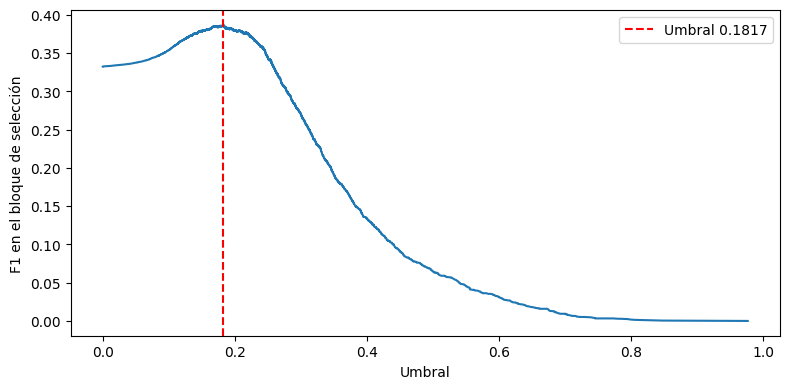

In [45]:
def elegir_umbral(y, probabilidades):
    precision, recall, umbrales = precision_recall_curve(y, probabilidades)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    pos = int(np.argmax(f1))
    return float(umbrales[pos]), umbrales, f1

X_ent_umbral = construir_features(train_hparam, incluir_categoria=USAR_CATEGORIA)
X_val_umbral = construir_features(val_umbral, referencia=train_hparam,
                                  incluir_categoria=USAR_CATEGORIA)
modelo_umbral = clone(configuracion)
modelo_umbral.fit(X_ent_umbral, train_hparam[TARGET].astype(int))
proba_umbral = modelo_umbral.predict_proba(X_val_umbral)[:, 1]
umbral_final, umbrales, curva_f1 = elegir_umbral(val_umbral[TARGET], proba_umbral)
print("Umbral seleccionado:", umbral_final)
display(pd.Series(metricas(val_umbral[TARGET], proba_umbral, umbral_final)))
plt.figure(figsize=(8, 4))
plt.plot(umbrales, curva_f1)
plt.axvline(umbral_final, color="red", linestyle="--", label=f"Umbral {umbral_final:.4f}")
plt.xlabel("Umbral")
plt.ylabel("F1 en el bloque de selección")
plt.legend()
plt.tight_layout()
plt.show()

12. Evaluación temporal del procedimiento cerrado
Se reentrena con las publicaciones anteriores al 15 de noviembre y se evalúa el resto de 2024, sin cambiar el umbral según ese resultado. Reentrenar puede modificar las probabilidades; esta evaluación mide el procedimiento completo.
La referencia original obtuvo F1 0,3792 en este período. La celda siguiente calcula el resultado de esta ejecución, sin copiar resultados antiguos. Precision mide cuántas alertas son correctas; recall, cuántas desiertas reales se detectan. F1 no es el porcentaje total de aciertos.

In [46]:
X_ent_eval = construir_features(train_umbral, incluir_categoria=USAR_CATEGORIA)
X_eval = construir_features(test_temporal, referencia=train_umbral,
                            incluir_categoria=USAR_CATEGORIA)
modelo_evaluacion = clone(configuracion)
modelo_evaluacion.fit(X_ent_eval, train_umbral[TARGET].astype(int))
proba_eval = modelo_evaluacion.predict_proba(X_eval)[:, 1]
metricas_eval = metricas(test_temporal[TARGET], proba_eval, umbral_final)
display(pd.Series(metricas_eval, name="Evaluación temporal actual"))
pred_eval = (proba_eval >= umbral_final).astype(int)
display(pd.DataFrame(
    confusion_matrix(test_temporal[TARGET], pred_eval, labels=[0, 1]),
    index=["Real: adjudicada", "Real: desierta"],
    columns=["Predice: adjudicada", "Predice: desierta"]
))

,Evaluación temporal actual
ap,0.351591
f1,0.378694
precision,0.267076
recall,0.650594
tasa_predicha,0.492078


,Predice: adjudicada,Predice: desierta
Real: adjudicada,6376,5258
Real: desierta,1029,1916


13. Entrenamiento final y CSV
Se reentrena con todo 2024, sin volver a seleccionar hiperparámetros ni umbral. Para 2025 los historiales se construyen solo con publicaciones de 2024. Las etiquetas de ejemplo de sample_submission.csv no se usan para aprender.
Se asocian las predicciones por ID y se conserva el orden de la plantilla. El CSV tiene únicamente id,y_desierta, sin índice adicional. El porcentaje marcado como desierto no es una estimación directa de la proporción real ni una medida de calidad.

In [47]:
X_2024 = construir_features(datos, incluir_categoria=USAR_CATEGORIA)
X_2025 = construir_features(test_df, referencia=datos, incluir_categoria=USAR_CATEGORIA)
modelo_final = clone(configuracion)
modelo_final.fit(X_2024, datos[TARGET].astype(int))
proba_2025 = modelo_final.predict_proba(X_2025)[:, 1]
assert np.isfinite(proba_2025).all()
pred_2025 = (proba_2025 >= umbral_final).astype(int)

por_id = pd.Series(pred_2025, index=test_df["id"])
submission = sample_submission_df[["id"]].copy()
submission[TARGET] = submission["id"].map(por_id)
assert submission[TARGET].notna().all()
submission[TARGET] = submission[TARGET].astype(int)
assert submission[TARGET].isin([0, 1]).all()
assert len(submission) == len(test_df)
assert submission.columns.tolist() == ["id", TARGET]
assert submission["id"].equals(sample_submission_df["id"])

submiss_csv = "submission_con_categoria.csv" if USAR_CATEGORIA else "submission_sin_categoria.csv"
submission.to_csv(submiss_csv, index=False)
display(submission.head())
print("Archivo generado:", submiss_csv)
print("Filas:", len(submission))
print("Porcentaje predicho como desierta:", round(pred_2025.mean() * 100, 2))

,id,y_desierta
0,47254358932,0
1,295671198916,0
2,214756376398,0
3,404842360472,0
4,899379189128,1


Archivo generado: submission_con_categoria.csv
Filas: 21829
Porcentaje predicho como desierta: 53.53


In [49]:
from google.colab import files
files.download(submiss_csv)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

14. Resumen de resultados históricos y conclusión
Esta tabla transcribe resultados observados en las capturas; no sustituye las salidas de una nueva ejecución.

| Experimento | Resultado registrado | Decisión |
|---|---|---|
| Búsqueda de C con texto, con/sin conteos | AP 0,337971 | C=0.3, sin balanceo; ganó con conteos |
| Vocabulario 20.000/50.000 y min_df 3/5 | AP 0,340632 | 50.000 términos, min_df=5 |
| Palabras individuales/parejas y acentos | Mejor AP 0,340632 | No mejoró; se conserva (1,2) y strip_accents=None; no se repite la búsqueda |
| Categoría completa en el texto | AP 0,342751 | Mejora local de 0,002119 |
| Umbral intermedio sin categoría | Umbral 0,1929; F1 0,3850 | Resultado de ajuste, no evaluación final |
| Entrega original en Kaggle | F1 mostrado 0,36760 | Referencia histórica |
| Entrega con categoría en Kaggle | F1 mostrado 0,36546 | Descenso de 0,00214 |

Las mejoras locales fueron pequeñas y no se trasladaron al puntaje mostrado por Kaggle. No se puede atribuir el descenso solo a la categoría: también cambiaron vocabulario y umbral. El resultado mostrado en Kaggle tampoco garantiza el orden en su evaluación privada final.
El archivo histórico enviado fue submission_con_categoria.csv. Una nueva ejecución vuelve a aplicar la regla de selección por AP y puede generar otra versión si cambian datos, librerías o resultados numéricos. El puntaje histórico no se atribuye automáticamente al CSV recién generado.
Limitaciones: resultados usados repetidamente durante el desarrollo; disponibilidad real de las etiquetas no fechada; mejora pequeña sin estimación de incertidumbre; historial limitado a publicaciones disponibles en la referencia. No se utilizan tasas de desiertas por comprador ni etiquetas externas de prueba.
Depuración realizada: una definición por función, categoría controlada por argumento, un solo flujo de búsqueda, un solo ajuste final de umbral, una evaluación temporal y una generación de CSV. Se retiraron grillas originales duplicadas, árbol/bosque del flujo adicional, métricas e importaciones sin uso, tablas redundantes y el ajuste intermedio de umbral (conservado solo como antecedente). Las comprobaciones de integridad e historial se mantienen porque protegen la validez del experimento.